<a href="https://colab.research.google.com/github/Gloou-ui/NM/blob/main/%D0%9B%D0%A07_%D0%9B%D0%B8%D1%82%D0%B2%D0%B8%D0%BD_%D0%A4%D0%86%D0%A23_10_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

> **Примітка:** ноутбук налаштований для Google Colab. Дані завантажуються з Kaggle через KaggleHub; клітинку з ручним завантаженням CSV виконувати не потрібно. Запускайте комірки послідовно зверху вниз. Перший запуск може попросити підтвердити доступ до завантаження датасету.


### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [ ]:
# Варіант 1 вимкнено: використовуємо завантаження з KaggleHub.

In [22]:
!pip -q install kagglehub

import kagglehub
import os
from pathlib import Path

dataset_path = Path(kagglehub.dataset_download("unmoved/cure-the-princess"))

csv_files = list(dataset_path.rglob("data.csv"))
if not csv_files:
    csv_files = list(dataset_path.rglob("*.csv"))

if not csv_files:
    raise FileNotFoundError(f"У папці {dataset_path} не знайдено CSV-файл.")

csv_path = next((p for p in csv_files if p.name.lower() == "data.csv"), csv_files[0])
df = pd.read_csv(csv_path)

print("Завантажено файл:", csv_path.name)
print("Розмір датасету:", df.shape)
display(df.head())

Using Colab cache for faster access to the 'cure-the-princess' dataset.
Завантажено файл: data.csv
Розмір датасету: (2338, 14)


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [3]:
display(df.head())
print("Розмір датасету:", df.shape)
print("\nІнформація про стовпці:")
df.info()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


Розмір датасету: (2338, 14)

Інформація про стовпці:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB


In [4]:
print("Пропущені значення:")
display(df.isnull().sum())

print("Кількість повних дублікатів:", df.duplicated().sum())

Пропущені значення:


,0
Phoenix Feather,0
Unicorn Horn,0
Dragon's Blood,0
Mermaid Tears,0
Fairy Dust,0
Goblin Toes,0
Witch's Brew,0
Griffin Claw,0
Troll Hair,0
Kraken Ink,0


Кількість повних дублікатів: 0


In [5]:
display(df.describe(include="all").T)

,count,mean,std,min,25%,50%,75%,max
Phoenix Feather,2338.0,15.365697,8.669969,1.0,8.500,14.7,21.300,42.1
Unicorn Horn,2338.0,10.946749,7.225162,1.0,5.300,9.5,15.575,34.1
Dragon's Blood,2338.0,16.115654,8.372518,1.0,9.600,15.8,22.000,40.8
Mermaid Tears,2338.0,13.627973,7.545244,1.0,7.600,13.1,19.000,35.8
Fairy Dust,2338.0,15.069504,8.349340,1.0,8.625,14.5,20.700,40.4
Goblin Toes,2338.0,14.157271,7.831476,1.0,7.900,13.5,19.500,37.8
Witch's Brew,2338.0,12.328914,7.709753,1.0,6.325,11.2,16.900,37.3
Griffin Claw,2338.0,14.911206,8.132678,1.0,8.400,14.4,20.500,39.4
Troll Hair,2338.0,16.871685,9.579027,1.0,8.900,16.3,24.000,44.8
Kraken Ink,2338.0,14.890590,8.014197,1.0,8.800,14.4,20.400,39.5


**Висновок за первинним оглядом:**  
_Напишіть тут, чи є пропуски, дублікати та які особливості даних помітили._

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [6]:
if "Cured" not in df.columns:
    raise KeyError(f"Не знайдено цільовий стовпець 'Cured'. Наявні стовпці: {df.columns.tolist()}")

data = df.dropna(subset=["Cured"]).copy()

X = data.drop(columns=["Cured"])
y = data["Cured"]

non_numeric = X.select_dtypes(exclude=np.number).columns.tolist()
if non_numeric:
    raise TypeError(f"Знайдено нечислові ознаки: {non_numeric}. Потрібно окремо закодувати їх.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1870, 13)
X_test: (468, 13)
y_train: (1870,)
y_test: (468,)


### 5. Баланс класів на навчальній вибірці

In [7]:
print("Розподіл класів у навчальній вибірці:")
display(y_train.value_counts().sort_index().rename("Кількість"))
print("\nЧастка класів:")
display((y_train.value_counts(normalize=True).sort_index() * 100).round(2).rename("Частка, %"))

Розподіл класів у навчальній вибірці:


,Кількість
Cured,
0,941
1,929



Частка класів:


,"Частка, %"
Cured,
0,50.32
1,49.68


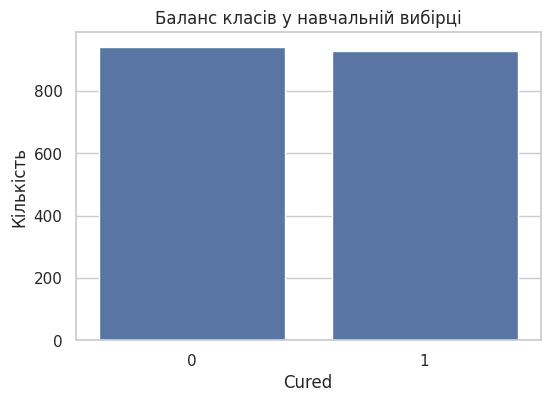

In [8]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train)
plt.title("Баланс класів у навчальній вибірці")
plt.xlabel("Cured")
plt.ylabel("Кількість")
plt.show()

**Висновок:**  
_Чи збалансовані класи? Чому це може вплинути на оцінку моделі?_

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

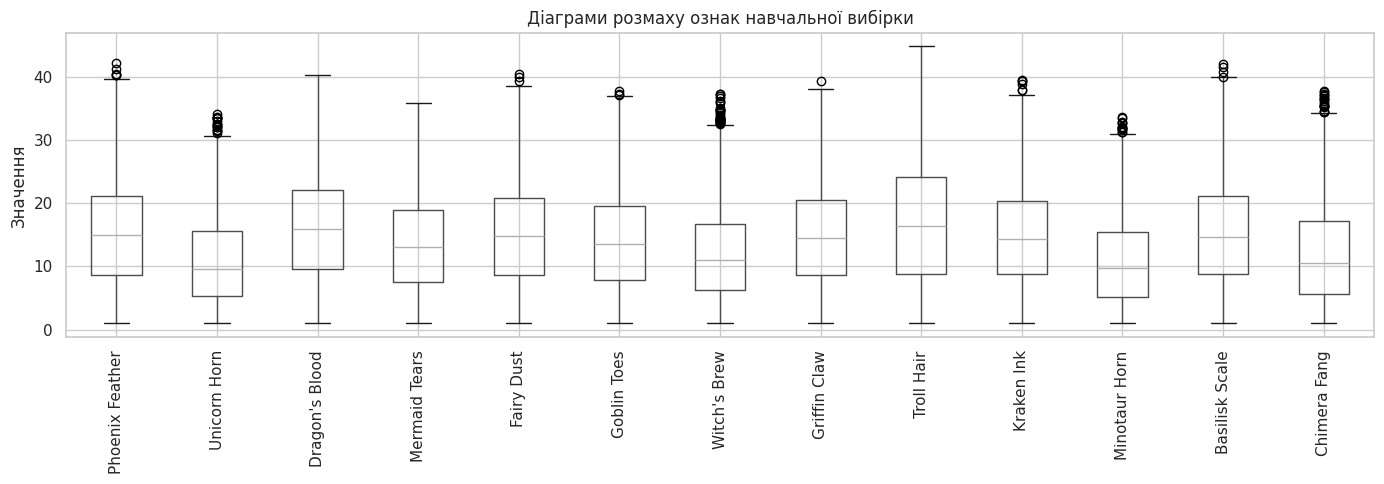

In [9]:
ax = X_train.boxplot(figsize=(14, 5), rot=90)
plt.title("Діаграми розмаху ознак навчальної вибірки")
plt.ylabel("Значення")
plt.tight_layout()
plt.show()

In [10]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_counts = ((X_train < lower_bound) | (X_train > upper_bound)).sum()
outlier_counts = outlier_counts.sort_values(ascending=False)

print("Кількість потенційних викидів за ознаками:")
display(outlier_counts.to_frame("Кількість викидів"))

Кількість потенційних викидів за ознаками:


,Кількість викидів
Witch's Brew,31
Chimera Fang,18
Unicorn Horn,17
Minotaur Horn,13
Kraken Ink,6
Phoenix Feather,5
Basilisk Scale,4
Fairy Dust,3
Goblin Toes,3
Griffin Claw,1


**Висновок про викиди:**  
_У яких ознаках їх найбільше? Чому не варто без перевірки видаляти всі такі рядки?_

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

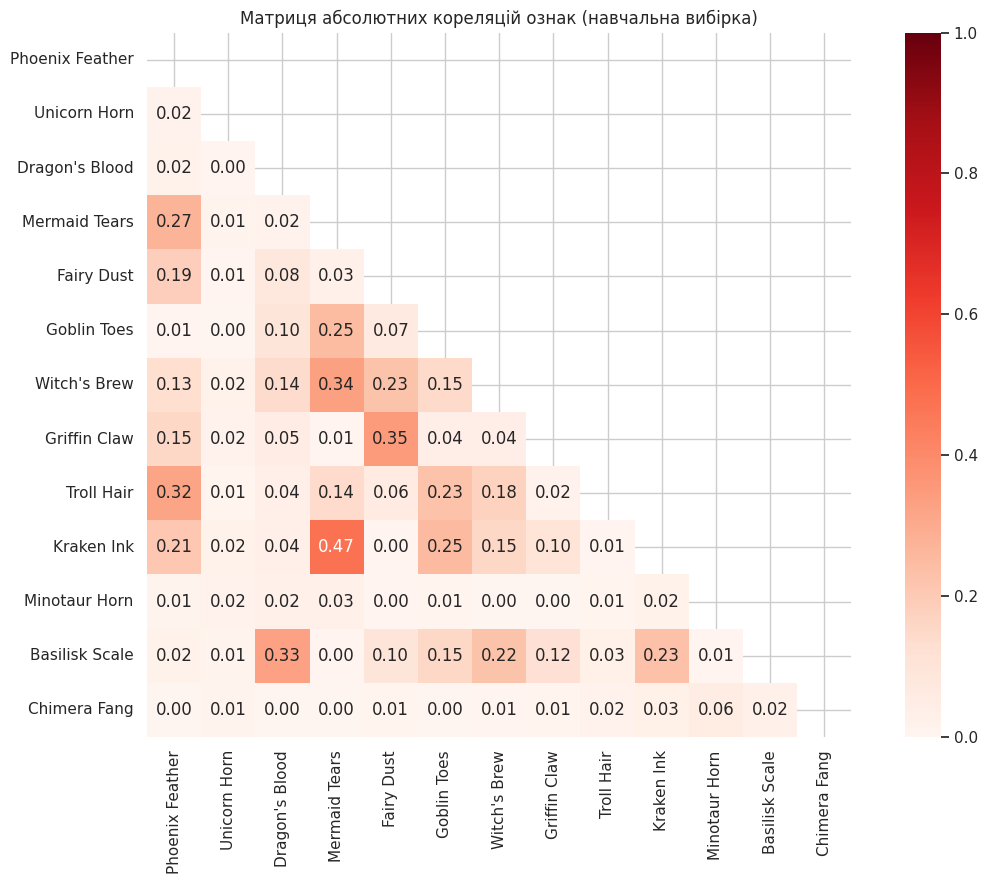

In [11]:
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool))

plt.figure(figsize=(12, 9))
sns.heatmap(mtx, mask=mask, annot=True, fmt=".2f", cmap="Reds",
            vmin=0, vmax=1, square=True)
plt.title("Матриця абсолютних кореляцій ознак (навчальна вибірка)")
plt.tight_layout()
plt.show()

In [12]:
train_with_target = pd.concat([X_train, y_train.rename("Cured")], axis=1)
target_corr = train_with_target.corr(numeric_only=True)["Cured"].drop("Cured")
target_corr = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index)

print("Кореляція ознак із цільовою змінною Cured:")
display(target_corr.to_frame("Кореляція з Cured"))

Кореляція ознак із цільовою змінною Cured:


,Кореляція з Cured
Troll Hair,0.504026
Witch's Brew,0.237690
Basilisk Scale,-0.055086
Goblin Toes,0.049919
Kraken Ink,-0.037099
Phoenix Feather,0.024068
Unicorn Horn,-0.021990
Griffin Claw,-0.020528
Chimera Fang,0.018197
Dragon's Blood,0.016741


**Висновок про кореляції:**  
_Назвіть пари найбільш корельованих ознак та ознаки з найсильнішим зв’язком із Cured._

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [13]:
imputer = SimpleImputer(strategy="median")
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test), columns=X_test.columns, index=X_test.index
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Навчальні дані стандартизовано:", X_train_scaled.shape)
print("Тестові дані стандартизовано:", X_test_scaled.shape)

Навчальні дані стандартизовано: (1870, 13)
Тестові дані стандартизовано: (468, 13)


### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [14]:
model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nЗвіт класифікації:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8526

Звіт класифікації:
              precision    recall  f1-score   support

           0       0.86      0.84      0.85       236
           1       0.84      0.86      0.85       232

    accuracy                           0.85       468
   macro avg       0.85      0.85      0.85       468
weighted avg       0.85      0.85      0.85       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

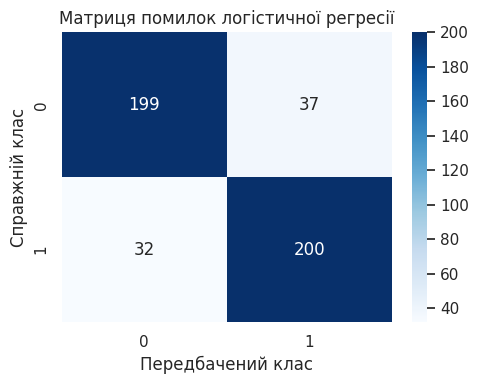

Порядок класів у матриці: [0 1]


In [15]:
conf = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(conf, annot=True, fmt="d", cmap="Blues")
plt.title("Матриця помилок логістичної регресії")
plt.xlabel("Передбачений клас")
plt.ylabel("Справжній клас")
plt.tight_layout()
plt.show()

print("Порядок класів у матриці:", np.unique(y_test))

In [16]:
predictions = pd.DataFrame({
    "Справжній клас": y_test,
    "Передбачений клас": y_pred
}, index=y_test.index)

display(predictions.sample(n=min(10, len(predictions)), random_state=RANDOM_STATE))

,Справжній клас,Передбачений клас
1318,0,0
244,0,0
996,1,1
930,0,0
839,0,0
1251,1,1
335,1,1
1670,0,0
1118,0,0
2175,1,1


**Висновок щодо якості логістичної регресії:**  
_Яких помилок більше? Чи достатньо однієї метрики Accuracy?_

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [17]:
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["lbfgs", "liblinear"],
    "max_iter": [500, 1000, 2000]
}

param_dist = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    "solver": ["lbfgs", "liblinear", "saga"],
    "max_iter": [500, 1000, 1500, 2000, 3000]
}

print("Параметри для GridSearchCV:")
print(param_grid)
print("\nПараметри для RandomizedSearchCV:")
print(param_dist)

Параметри для GridSearchCV:
{'C': [0.01, 0.1, 1, 10, 100], 'solver': ['lbfgs', 'liblinear'], 'max_iter': [500, 1000, 2000]}

Параметри для RandomizedSearchCV:
{'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000], 'solver': ['lbfgs', 'liblinear', 'saga'], 'max_iter': [500, 1000, 1500, 2000, 3000]}


In [18]:
grid_search = GridSearchCV(
    estimator=LogisticRegression(random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)
grid_search.fit(X_train_scaled, y_train)

print("Найкращі параметри GridSearchCV:", grid_search.best_params_)
print("Найкраща середня accuracy на CV:", round(grid_search.best_score_, 4))

Найкращі параметри GridSearchCV: {'C': 10, 'max_iter': 500, 'solver': 'lbfgs'}
Найкраща середня accuracy на CV: 0.8749


In [19]:
random_search = RandomizedSearchCV(
    estimator=LogisticRegression(random_state=RANDOM_STATE),
    param_distributions=param_dist,
    n_iter=15,
    cv=3,
    scoring="accuracy",
    random_state=RANDOM_STATE,
    n_jobs=-1
)
random_search.fit(X_train_scaled, y_train)

print("Найкращі параметри RandomizedSearchCV:", random_search.best_params_)
print("Найкраща середня accuracy на CV:", round(random_search.best_score_, 4))

Найкращі параметри RandomizedSearchCV: {'solver': 'saga', 'max_iter': 1000, 'C': 10}
Найкраща середня accuracy на CV: 0.8749


In [20]:
if grid_search.best_score_ >= random_search.best_score_:
    best_search = grid_search
    best_search_name = "GridSearchCV"
else:
    best_search = random_search
    best_search_name = "RandomizedSearchCV"

best_model = best_search.best_estimator_
y_pred_tuned = best_model.predict(X_test_scaled)

print("Обраний метод:", best_search_name)
print("Найкращі параметри:", best_search.best_params_)
print("Accuracy налаштованої моделі:", round(accuracy_score(y_test, y_pred_tuned), 4))
print("\nЗвіт класифікації:")
print(classification_report(y_test, y_pred_tuned, zero_division=0))

Обраний метод: GridSearchCV
Найкращі параметри: {'C': 10, 'max_iter': 500, 'solver': 'lbfgs'}
Accuracy налаштованої моделі: 0.8504

Звіт класифікації:
              precision    recall  f1-score   support

           0       0.86      0.84      0.85       236
           1       0.84      0.86      0.85       232

    accuracy                           0.85       468
   macro avg       0.85      0.85      0.85       468
weighted avg       0.85      0.85      0.85       468



**Висновок про підбір параметрів:**  
_Який метод пошуку обрав які параметри? Чи покращилась якість порівняно з базовою моделлю?_

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [21]:
comparison_models = {
    "Логістична регресія": model,
    "SVM (SVC)": SVC(),
    "Дерево рішень": DecisionTreeClassifier(random_state=RANDOM_STATE)
}

comparison_rows = []
comparison_predictions = {}

for name, estimator in comparison_models.items():
    if name == "Логістична регресія":
        fitted_model = estimator
        Xtr, Xte = X_train_scaled, X_test_scaled
    else:
        fitted_model = estimator
        Xtr, Xte = X_train_imputed, X_test_imputed

    fitted_model.fit(Xtr, y_train)
    pred = fitted_model.predict(Xte)
    comparison_predictions[name] = pred

    comparison_rows.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, pred),
        "F1-score": f1_score(y_test, pred, zero_division=0)
    })

comparison_table = pd.DataFrame(comparison_rows).set_index("Модель").sort_values(
    by="F1-score", ascending=False
)
display(comparison_table.round(4))

best_model_name = comparison_table["F1-score"].idxmax()
print("Найкраща модель за F1-score:", best_model_name)

,Accuracy,F1-score
Модель,,
SVM (SVC),0.9423,0.9417
Логістична регресія,0.8526,0.8529
Дерево рішень,0.8269,0.8266


Найкраща модель за F1-score: SVM (SVC)


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  
ми провели аналіз датасету Cure the Princess та навчились робити моделі машинного навчання для розв'язання задачі бінарної класифікації.

Під час первинного аналізу дослідили структуру та розмір датасету, также перевіряли щоб не було пропусків і повторів, а також розглянуто основні статистичні характеристики даних.

Дослідили викиди за правилом 1,5 IQR та кореляційний аналіз який допоміг визначити особливості ознак і зв'язок між ними.

Для прогнозування результату ми створили модель логістичної регресії. Її якість оцінювалася за допомогою Accuracy, precision, recall та F1-score. Що дало змогу оцінити не лише загальну точність, а й здатність моделі правильно визначати кожен клас.

За допомогою GridSearchCV та RandomizedSearchCV зробили підбір гіперпараметрів логістичної регресії. Це дозволило знайти параметри, за яких модель показувала кращий результат на перехресній перевірці, та порівняти їх із базовою моделлю.

Також побудовали та порівняно три моделі: логістичну регресію, метод опорних векторів (SVC) і дерево рішень. Їх оцінили за допомогою метрики Accuracy та F1-score. Найкраща модель була та яка показала найкраще співвідношення цих показників.

---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.